In [ ]:

import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob

from PIL import Image
from torchvision import transforms

import pandas as pd
import re as regex_module
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster

from ultralytics import YOLO

from pipeline.preprocessing import Repair, Normalizer
from pipeline.feature_learning.vae import VAE
from pipeline.feature_learning.vae_classifier import VAEClassifier
from pipeline.clustering import HierarchicalClustering
from pipeline.evaluation import EvaluationWithGroundTruth, EvaluationWithNoGroundTruth

# PIPELINE

In [2]:
run_id = "run_2026-09-04_class" 

## Preprocessing

### Shard selection and  background cleaning

In [ ]:

#image_paths = glob.glob("/caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/2012_Survey Gladiatorenschule/**/*.jpg", recursive=True)
image_path= "/caa/Homes01/alaczko/Diploma/Diploma/data/raw"
 
br=BackgroundEraser(input_path=image_path, batch_size=32, num_workers=16, run_id=run_id)
#todo "detected 6171 shards, but erased len is 2800"   
erased=br.run()

### Resize & Crop

In [ ]:
crop_step = Normalizer(input_path=erased, background_color=(255, 255, 255), run_id=run_id)

cropped= crop_step.run()

### Enhancing Picture Quality

In [ ]:
repair_step = Repair(
    input_path=cropped,
    max_distance=20,
    output_thickness=3,   # ← ez az új paraméter
    run_id=run_id
)

result_path = repair_step.run()

## Feature Learning

### VAE

In [ ]:
result_path="/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2026-09-01/PreprocessingStep/Repair"

#result_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256"

In [ ]:
vae = VAE(input_path=result_path, f=4, n=3, s=1, k=128, run_id=run_id)  # k=128 latent dimension
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

results = vae.run('train_model', epochs=1000, lr=1e-6, batch_size=128)

torch.save(vae.state_dict(), "../models/feature_learning/legion.pt")

In [ ]:
results = vae.extract_features( batch_size=128)

In [ ]:
results

In [ ]:
results.to_csv("../data/pipeline/default_run/features.csv", index=False)

#### Testing Feature Learning

In [ ]:
vae= VAE(input_path="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256", f=4, n=3, s=1, k=128)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

vae.load_state_dict(torch.load("../models/feature_learning/roco_all_og.pt", map_location=device))

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

img_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/test-roco.png"
original_img = Image.open(img_path)
input_tensor = transform(original_img).unsqueeze(0).to(device) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae(input_tensor)

orig_np = input_tensor.squeeze().cpu().numpy()
recon_np = reconstructed.squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Classifier

In [2]:
result_path="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256"


In [3]:
vae= VAE(input_path="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256", f=4, n=3, s=1, k=128)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

vae.load_state_dict(torch.load("../models/feature_learning/roco_all_og.pt", map_location=device))


Output path for step VAE : ../data/pipeline/default_run/Module/VAE


<All keys matched successfully>

In [5]:
from pipeline.feature_learning import VAEClassifier

labels_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_results.csv"

classifier = VAEClassifier(
    input_path=result_path,          # a VAE bemeneti képeinek elérési útja
    vae=vae,                         # a fentebb betanított VAE
    num_classes=28,
    labels_path=labels_path,
    freeze_encoder=True,             # először csak a classifier tanul
    output_path="../models/feature_learning/vae_classifier",
    run_id=run_id,
).to(device)

history = classifier.run(
    epochs=200,
    lr=1e-4,
    batch_size=128,
    validation_size=0.2,
    num_workers=16,
)

history

Output path for step VAEClassifier : ../models/feature_learning/vae_classifier
Found 4611 labelled images in /caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256
Using 18 classes and 4595 labelled images after excluding classes with fewer than 10 samples
[1/200] loss=2.9016 | train_acc=0.0773 | val_acc=0.0642 | val_acc_smoothed=0.0642
[2/200] loss=2.8980 | train_acc=0.0767 | val_acc=0.0653 | val_acc_smoothed=0.0647
[3/200] loss=2.8903 | train_acc=0.0830 | val_acc=0.0653 | val_acc_smoothed=0.0649
[4/200] loss=2.8881 | train_acc=0.0887 | val_acc=0.0664 | val_acc_smoothed=0.0653
[5/200] loss=2.8790 | train_acc=0.0811 | val_acc=0.0675 | val_acc_smoothed=0.0657
[6/200] loss=2.8721 | train_acc=0.0895 | val_acc=0.0653 | val_acc_smoothed=0.0657
[7/200] loss=2.8635 | train_acc=0.0968 | val_acc=0.0631 | val_acc_smoothed=0.0653
[8/200] loss=2.8683 | train_acc=0.0985 | val_acc=0.0642 | val_acc_smoothed=0.0652
[9/200] loss=2.8629 | train_acc=0.0944 | val_acc=0.0707 | val_acc_smoothed=0.0658
[1

,epoch,loss,train_accuracy,validation_accuracy,validation_accuracy_smoothed
0,1,2.901563,0.077258,0.064200,0.064200
1,2,2.898045,0.076714,0.065288,0.064744
2,3,2.890262,0.082971,0.065288,0.064926
3,4,2.888055,0.088683,0.066376,0.065288
4,5,2.878958,0.081066,0.067465,0.065724
...,...,...,...,...,...
69,70,2.185974,0.181175,0.182807,0.186616
70,71,2.197412,0.180631,0.181719,0.186181
71,72,2.265841,0.172198,0.180631,0.185201
72,73,2.187119,0.178999,0.184984,0.184331


### Clustering

In [4]:
df = pd.read_csv("../data/pipeline/roco_run/features.csv")

In [5]:
import numpy as np
import ast

def parse_feature_string(s):
    if isinstance(s, str):
        cleaned = s.strip('[]')
        # tetszőleges mennyiségű whitespace -> egyetlen szóköz
        cleaned = regex_module.sub(r'\s+', ' ', cleaned).strip()
        return np.fromstring(cleaned, sep=' ')
    return np.asarray(s)

In [ ]:
df['features'] = df['features'].apply(parse_feature_string)
df['sigma'] = df['sigma'].apply(parse_feature_string)

In [ ]:
# Concatenate mu (mean) and sigma (log-variance) into one 256-dim vector per
# sample, so clustering uses everything the encoder outputs, not just mu.
mu_matrix = np.vstack(df['features'].values)
sigma_matrix = np.vstack(df['sigma'].values)
X = np.hstack([mu_matrix, sigma_matrix])

# 2. inaktív / szinte nulla varianciájú dimenziók kiszűrése (opcionális, de ajánlott)
variances = X.var(axis=0)
active_dims = variances > 1e-3   # threshold-öt finomítsd a saját adatodra
X_active = X[:, active_dims]

# 3. standardizálás (dimenziónkénti z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_active)

df["features_non_scaled"] = list(X)  # mu+sigma összefűzve, szűrés/skálázás előtt

# 4. opcionálisan visszaírhatod a df-be, hogy egyben tudd kezelni
df['features'] = list(X_scaled)

df.to_csv("../data/pipeline/roco_run/features_scaled.csv", index=False)

In [8]:
df.head()

,filename,features,features_non_scaled
0,BERT11-100b.png,"[-0.4591889344444607, -0.3811585452720912, -1....","[-0.67233, -0.28367, -1.7104, 2.5618, 1.4396, ..."
1,BERT11-101.png,"[-0.9307559124131908, -0.7066401604360796, -2....","[-1.198, -0.62523, -2.2841, 1.8371, 0.31463, 0..."
2,BERT11-102.png,"[-0.7964633398830504, -0.4842842637199389, -2....","[-1.0483, -0.39189, -2.2423, 2.3464, 0.4346, 1..."
3,BERT11-103.png,"[-0.616662001792095, -1.6070319326576445, -1.0...","[-0.84787, -1.5701, -1.0696, 2.5938, -0.013319..."
4,BERT11-104.png,"[-0.9327294839533798, -0.26644523916645557, -2...","[-1.2002, -0.16329, -2.124, 2.1455, 1.3306, 0...."


In [9]:
clustering_step = HierarchicalClustering(
    input_path="../data/pipeline/roco_run/features_scaled.csv",
    cluster_num=55
)
# result= clustering_step.run()


#result = clustering_step.compare_all()

Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering


In [10]:
result= clustering_step.run()

In [11]:
np.unique(result, return_counts=True)

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55], dtype=int32),
 array([   7,   10,    2,    3,    1,    1,    1,    1,    4,    9,    3,    3,   12,   15,    4,    5,    1,    1,    8,   15,    7,    3,   11,    6,   37,   44,   54,    1,  380,  117,   77,   53,   36, 2335,   65,  365,    5,  460,   18,  193,   12,   31,   52,    2,   96,    7,    9,    4,    1,    7,    6,   17,
           1,    1,    1]))

#### Silhouette Score (no ground truth needed)

In [12]:
# Unsupervised evaluation: uses only the feature vectors + predicted cluster
# labels, so it works even before/without matching against ground-truth types.
silhouette_step = EvaluationWithNoGroundTruth(features=clustering_step.vectors, y_pred=result)
silhouette_step.run()

Predicted labels: [40 40 40 ... 36 38 38]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.043387298635158285
-----




In [13]:
df["pred"] = list(result)

In [14]:
df["filename"] = df["filename"].str.rsplit(".", n=1).str[0]

In [15]:
roco_labels = pd.read_csv("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_results.csv")

In [16]:
new_df = pd.merge(
    df,
    roco_labels,
    left_on="filename",
    right_on="ID",
    how="inner"
)

In [17]:
new_df = new_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

In [18]:
new_df

,filename,features,features_non_scaled,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.4591889344444607, -0.3811585452720912, -1....","[-0.67233, -0.28367, -1.7104, 2.5618, 1.4396, ...",40,BERT11-100b,pan,BERT11
1,BERT11-101,"[-0.9307559124131908, -0.7066401604360796, -2....","[-1.198, -0.62523, -2.2841, 1.8371, 0.31463, 0...",40,BERT11-101,pan,BERT11
2,BERT11-102,"[-0.7964633398830504, -0.4842842637199389, -2....","[-1.0483, -0.39189, -2.2423, 2.3464, 0.4346, 1...",40,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.616662001792095, -1.6070319326576445, -1.0...","[-0.84787, -1.5701, -1.0696, 2.5938, -0.013319...",36,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.9327294839533798, -0.26644523916645557, -2...","[-1.2002, -0.16329, -2.124, 2.1455, 1.3306, 0....",40,BERT11-104,pan,BERT11
...,...,...,...,...,...,...,...
4592,STAN01-9.I2FF9.246,"[-0.17702202887578766, 0.09054965920831015, 2....","[-0.35779, 0.21134, 2.3581, 1.1562, 1.5436, 0....",38,STAN01-9.I2FF9.246,lid,STAN01
4593,STAN01-9.I2FF9.247,"[0.37808982070103847, -0.8402404720826167, -1....","[0.26101, -0.76543, -1.2004, 2.4863, 0.086412,...",36,STAN01-9.I2FF9.247,lid,STAN01
4594,STAN01-9.I2FF9.248,"[0.03624928838082939, -0.8031620974309279, -0....","[-0.12005, -0.72652, -0.15221, 2.1776, 0.53842...",36,STAN01-9.I2FF9.248,lid,STAN01
4595,STAN01-9.I2FF9.249,"[0.01886391726770902, 0.30844585935878904, 0.9...","[-0.13943, 0.44, 0.91541, 1.3445, 1.0264, 0.37...",38,STAN01-9.I2FF9.249,lid,STAN01


In [19]:
eval_step = EvaluationWithGroundTruth(y_true=new_df["TypeRev"].values, y_pred=new_df["pred"].values)

Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [40 40 40 ... 36 38 38]


In [20]:
eval_step.run()

-----
Evaluation results: 
ACC = 0.28322819229932567, 
ARI = 0.06986641230531142, 
NMI = 0.16907422690069215
-----




In [ ]:
features_path = "../data/pipeline/roco_run/features_scaled.csv"

cluster_numbers = range(3, 10)
metric_results = []

# A features.csv sorrendjében találhatók a klaszterezés bemenetei
features_df = pd.read_csv(features_path)

features_df["filename"] = (
    features_df["filename"]
    .astype(str)
    .str.strip()
    .str.rsplit(".", n=1)
    .str[0]
)


In [22]:
for cluster_num in cluster_numbers:
    clustering_step = HierarchicalClustering(
        input_path=features_path,
        cluster_num=cluster_num
    )

    predicted_labels = clustering_step.run()

    # Unsupervised metric: doesn't need the ground-truth join below, so it's
    # computed on every sample that went into clustering.
    silhouette_step = EvaluationWithNoGroundTruth(
        features=clustering_step.vectors, y_pred=predicted_labels
    )
    silhouette_step.run()

    predictions_df = features_df[["filename"]].copy()
    predictions_df["pred"] = predicted_labels

    # Az új klasztercímkék hozzárendelése a meglévő dataframe-hez
    current_df = pd.merge(
        predictions_df,
        roco_labels,
        left_on="filename",
        right_on="ID",
        how="inner"
    )

    current_df = current_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

    y_true = current_df["TypeRev"].to_numpy()
    y_pred = current_df["pred"].to_numpy()


    eval_step = EvaluationWithGroundTruth(y_true=y_true, y_pred=y_pred)

    eval_step.run()

    metric_results.append({
        "cluster_num": cluster_num,
        "ACC": eval_step.acc,
        "ARI": eval_step.ari,
        "NMI": eval_step.nmi,
        "Silhouette": silhouette_step.silhouette,
        "sample_count": len(current_df),
        "predicted_cluster_count": current_df["pred"].nunique(),
    })

metrics_df = pd.DataFrame(metric_results)
metrics_df

Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering
Predicted labels: [7 7 7 ... 7 7 7]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.0943114760679403
-----


Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [7 7 7 ... 7 7 7]
-----
Evaluation results: 
ACC = 0.24559495323036762, 
ARI = 0.001623747771687855, 
NMI = 0.02557106539280918
-----


Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering
Predicted labels: [7 7 7 ... 7 7 7]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.07401484651613592
-----


Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [7 7 7 ... 7 7 7]
-----
Evaluation results: 
ACC = 0.24559495323036762, 
ARI = 0.0016835426398254677, 
NMI = 0.025981456670482135
-----


Output path for step HierarchicalClustering :

,cluster_num,ACC,ARI,NMI,Silhouette,sample_count,predicted_cluster_count
0,10,0.245595,0.001624,0.025571,0.094311,4597,10
1,11,0.245595,0.001684,0.025981,0.074015,4597,11
2,12,0.245595,0.001683,0.026112,0.071820,4597,12
3,13,0.246248,0.001699,0.030511,0.067436,4597,13
4,14,0.246248,0.001699,0.030836,0.056974,4597,14
...,...,...,...,...,...,...,...
85,95,0.250598,0.090253,0.188677,0.032159,4597,94
86,96,0.249946,0.090225,0.188962,0.033759,4597,95
87,97,0.249728,0.090214,0.189224,0.033132,4597,96
88,98,0.249728,0.090214,0.189317,0.033035,4597,97


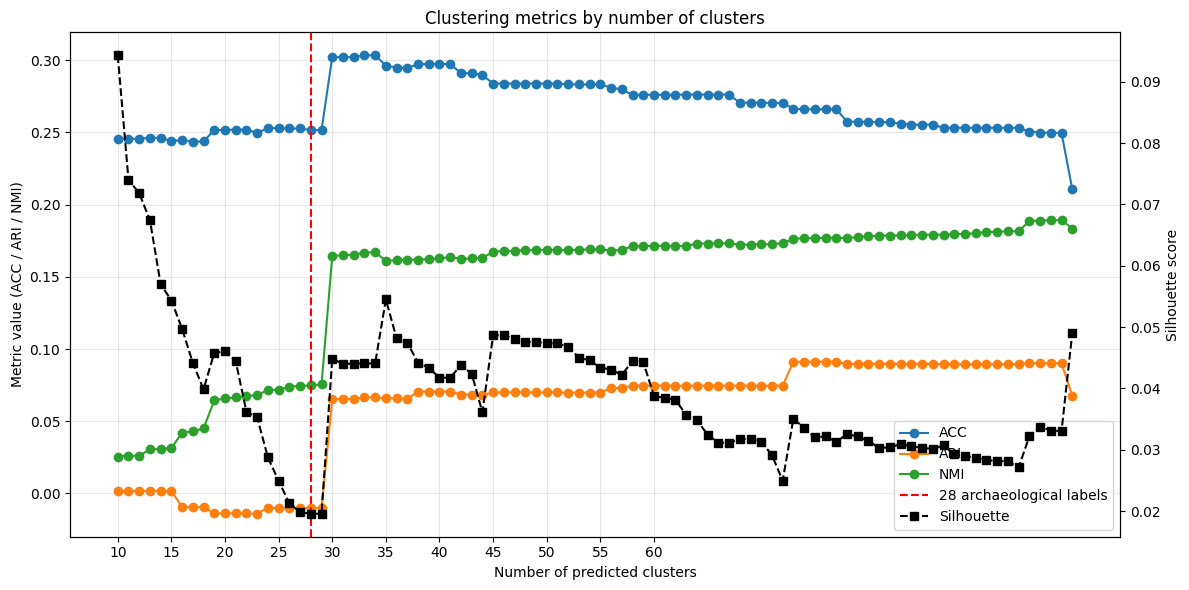

In [23]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ACC"],
    marker="o",
    label="ACC"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ARI"],
    marker="o",
    label="ARI"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["NMI"],
    marker="o",
    label="NMI"
)

ax1.axvline(
    28,
    color="red",
    linestyle="--",
    label="28 archaeological labels"
)

ax1.set_xlabel("Number of predicted clusters")
ax1.set_ylabel("Metric value (ACC / ARI / NMI)")
ax1.set_xticks(range(10, 61, 5))
ax1.grid(alpha=0.3)

# Silhouette score has a different range ([-1, 1], unsupervised - no ground
# truth involved) than ACC/ARI/NMI, so it gets its own y-axis rather than
# being squashed onto the same 0-1 scale.
ax2 = ax1.twinx()
ax2.plot(
    metrics_df["cluster_num"],
    metrics_df["Silhouette"],
    marker="s",
    color="black",
    linestyle="--",
    label="Silhouette",
)
ax2.set_ylabel("Silhouette score")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Clustering metrics by number of clusters")
plt.tight_layout()
plt.show()

In [24]:
new_df

,filename,features,features_non_scaled,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.4591889344444607, -0.3811585452720912, -1....","[-0.67233, -0.28367, -1.7104, 2.5618, 1.4396, ...",40,BERT11-100b,pan,BERT11
1,BERT11-101,"[-0.9307559124131908, -0.7066401604360796, -2....","[-1.198, -0.62523, -2.2841, 1.8371, 0.31463, 0...",40,BERT11-101,pan,BERT11
2,BERT11-102,"[-0.7964633398830504, -0.4842842637199389, -2....","[-1.0483, -0.39189, -2.2423, 2.3464, 0.4346, 1...",40,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.616662001792095, -1.6070319326576445, -1.0...","[-0.84787, -1.5701, -1.0696, 2.5938, -0.013319...",36,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.9327294839533798, -0.26644523916645557, -2...","[-1.2002, -0.16329, -2.124, 2.1455, 1.3306, 0....",40,BERT11-104,pan,BERT11
...,...,...,...,...,...,...,...
4592,STAN01-9.I2FF9.246,"[-0.17702202887578766, 0.09054965920831015, 2....","[-0.35779, 0.21134, 2.3581, 1.1562, 1.5436, 0....",38,STAN01-9.I2FF9.246,lid,STAN01
4593,STAN01-9.I2FF9.247,"[0.37808982070103847, -0.8402404720826167, -1....","[0.26101, -0.76543, -1.2004, 2.4863, 0.086412,...",36,STAN01-9.I2FF9.247,lid,STAN01
4594,STAN01-9.I2FF9.248,"[0.03624928838082939, -0.8031620974309279, -0....","[-0.12005, -0.72652, -0.15221, 2.1776, 0.53842...",36,STAN01-9.I2FF9.248,lid,STAN01
4595,STAN01-9.I2FF9.249,"[0.01886391726770902, 0.30844585935878904, 0.9...","[-0.13943, 0.44, 0.91541, 1.3445, 1.0264, 0.37...",38,STAN01-9.I2FF9.249,lid,STAN01


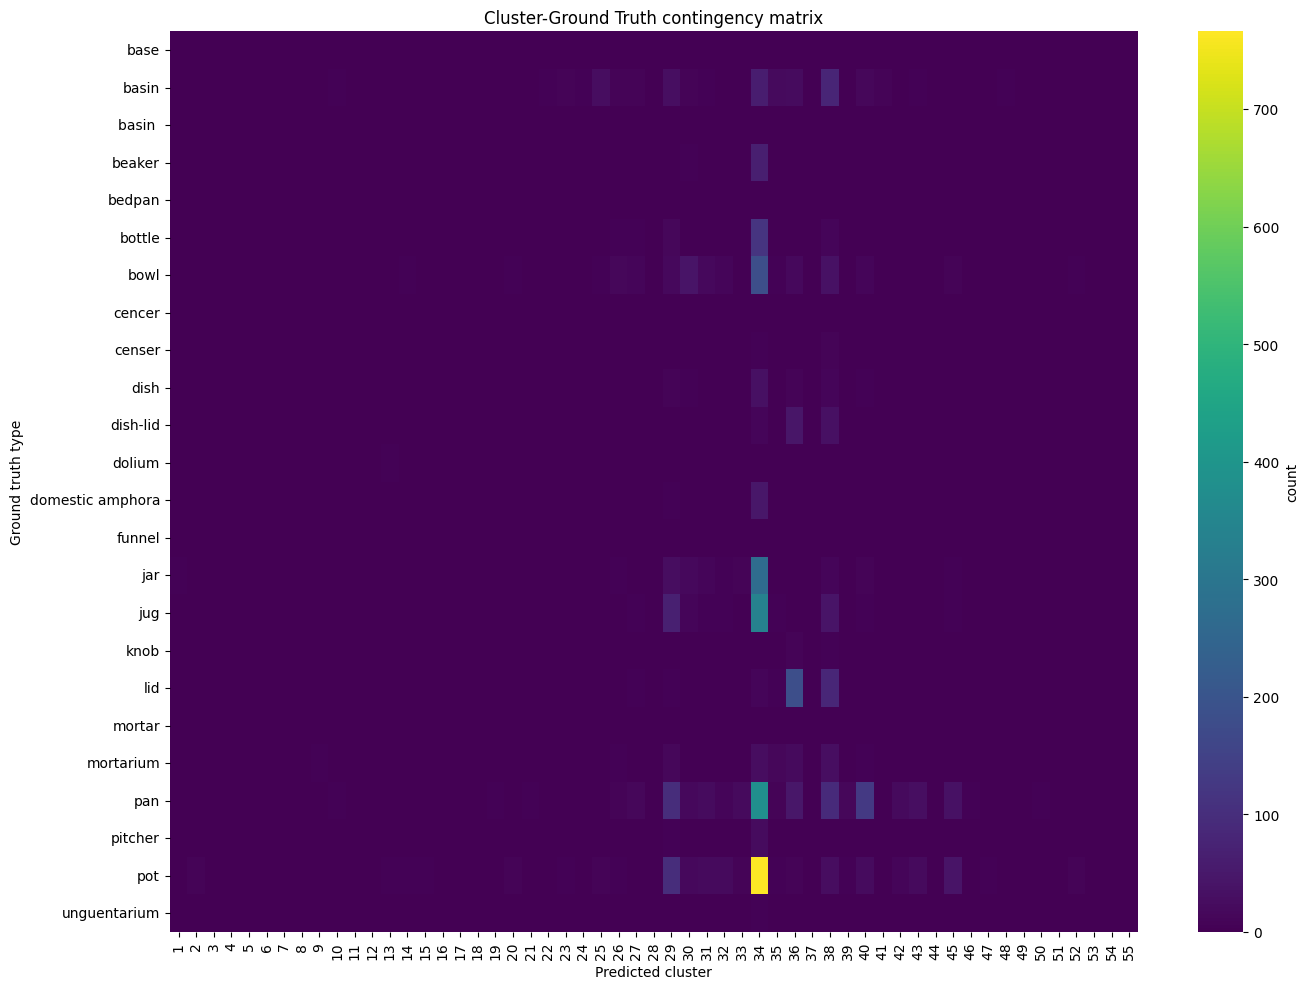

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df-ben legyen egy 'pred' (predikált cluster) és egy 'true_label' (ground truth) oszlop
contingency = pd.crosstab(new_df['TypeRev'], new_df['pred'])

plt.figure(figsize=(14, 10))
sns.heatmap(contingency, annot=False, cmap='viridis', cbar_kws={'label': 'count'})
plt.xlabel('Predicted cluster')
plt.ylabel('Ground truth type')
plt.title('Cluster-Ground Truth contingency matrix')
plt.tight_layout()
plt.show()